NYC TAXI PROJECT - OPTIMIZED EXECUTION

Available files:
yellow_tripdata_2015-01.csv
yellow_tripdata_2016-01.csv
yellow_tripdata_2016-02.csv
yellow_tripdata_2016-03.csv

Selected file: /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv

Dataset loaded.
Rows: 50000
Columns: 19

Dataset columns:
['vendorid', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'ratecodeid', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

Feature engineering completed.
Location features completed.
Final dataset size: (49703, 38)

PILLAR A - SURGE TIER CLASSIFICATION

Surge Tier Distribution:
Surge_Tier
1    26884
2    22753
0       66
Name: count, dtype: int64

Training fast classification model...

Classification Results
Accuracy: 0.99859
Macro F1 Score: 0.89678

Classificat

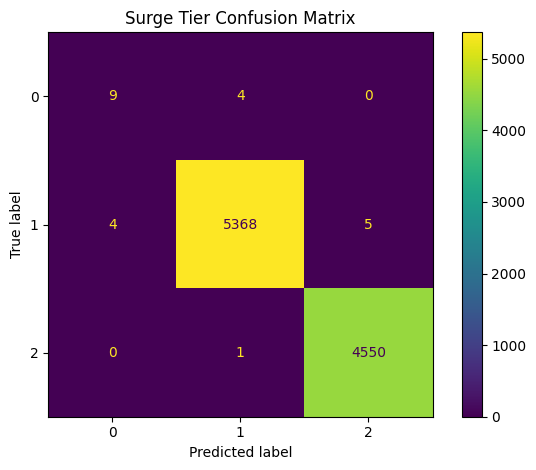


PILLAR B - CEPI REGRESSION

Training fast CEPI regression model...

CEPI Results
RMSE: 0.00544
MAE: 0.00241
R2 Score: 0.99839


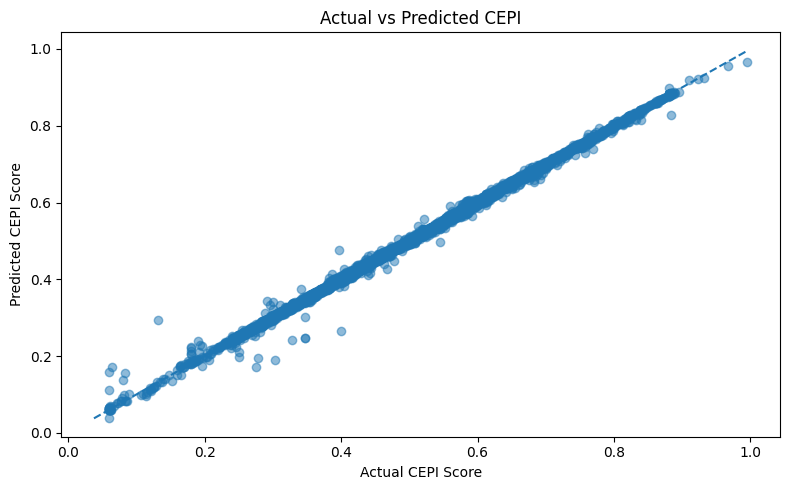


PILLAR C - GHOST CORRIDOR CLUSTERING

Finding optimal cluster count...
K = 2 | Silhouette = 0.22785
K = 3 | Silhouette = 0.13319
K = 4 | Silhouette = 0.25622
K = 5 | Silhouette = 0.14703
K = 6 | Silhouette = 0.1906

Clustering Results
Best K: 4
Silhouette Score: 0.25622

Cluster Distribution:
Ghost_Corridor_Cluster
0    31168
1     8300
2     9480
3      755
Name: count, dtype: int64


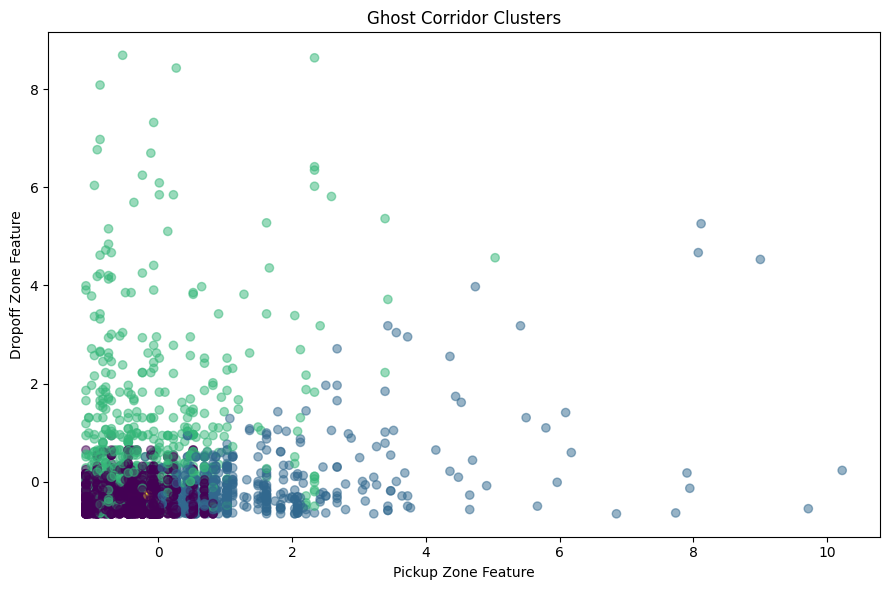


Generating final predictions...

FINAL MODEL COMPARISON
        Pillar                      Algorithm           Metric    Score
Classification HistGradientBoostingClassifier         Macro F1 0.896782
    Regression  HistGradientBoostingRegressor             RMSE 0.005443
    Clustering                MiniBatchKMeans Silhouette Score 0.256219

ALL THREE PILLARS COMPLETED SUCCESSFULLY

PILLAR A - CLASSIFICATION
Macro F1: 0.89678
Accuracy: 0.99859

PILLAR B - REGRESSION
RMSE: 0.00544
MAE: 0.00241
R2: 0.99839

PILLAR C - CLUSTERING
Best K: 4
Silhouette: 0.25622

PREDICTION SAMPLE
   Trip_ID  Surge_Tier_Prediction  CEPI_Score_Prediction  \
0        0                      2               0.640481   
1        1                      1               0.442772   
2        2                      1               0.444743   
3        3                      2               0.146220   
4        4                      1               0.456049   
5        5                      1               0.244729

In [3]:

import os
import glob
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    silhouette_score
)

warnings.filterwarnings("ignore")
np.random.seed(42)

# ============================================================
# 1. SETTINGS
# ============================================================

DATA_FOLDER = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

OUTPUT_FOLDER = "/kaggle/working/taxi_project_outputs"

MAX_ROWS = 50000
CLUSTER_MAX_ROWS = 30000
SILHOUETTE_SAMPLE = 2000

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("=" * 60)
print("NYC TAXI PROJECT - OPTIMIZED EXECUTION")
print("=" * 60)

# ============================================================
# 2. AUTOMATIC DATASET LOADING
# ============================================================

if not os.path.isdir(DATA_FOLDER):
    raise FileNotFoundError(
        "Dataset folder not found: " + DATA_FOLDER
    )

all_files = []

for ext in ["*.parquet", "*.pq", "*.csv", "*.csv.gz"]:
    all_files.extend(
        glob.glob(
            os.path.join(DATA_FOLDER, "**", ext),
            recursive=True
        )
    )

all_files = sorted(set(all_files))

if not all_files:
    raise FileNotFoundError(
        "No CSV or Parquet files found."
    )

print("\nAvailable files:")

for f in all_files:
    print(os.path.basename(f))

parquet_files = [
    f for f in all_files
    if f.lower().endswith((".parquet", ".pq"))
]

csv_files = [
    f for f in all_files
    if f.lower().endswith((".csv", ".csv.gz"))
]

if parquet_files:
    DATA_PATH = parquet_files[0]
else:
    DATA_PATH = csv_files[0]

print("\nSelected file:", DATA_PATH)

if DATA_PATH.lower().endswith((".parquet", ".pq")):

    try:
        import pyarrow.parquet as pq

        parquet_file = pq.ParquetFile(DATA_PATH)

        batches = parquet_file.iter_batches(
            batch_size=MAX_ROWS
        )

        first_batch = next(batches, None)

        if first_batch is None:
            raise ValueError("Selected Parquet file is empty.")

        df = first_batch.to_pandas()

    except ImportError:
        df = pd.read_parquet(DATA_PATH).head(MAX_ROWS)

else:
    df = pd.read_csv(
        DATA_PATH,
        nrows=MAX_ROWS,
        low_memory=False
    )

if len(df) > MAX_ROWS:
    df = df.sample(
        n=MAX_ROWS,
        random_state=42
    )

df = df.reset_index(drop=True)

print("\nDataset loaded.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

# ============================================================
# 3. NORMALIZE COLUMNS
# ============================================================

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df = df.loc[:, ~df.columns.duplicated()].copy()

aliases = {
    "tpep_pickup_datetime": "pickup_datetime",
    "lpep_pickup_datetime": "pickup_datetime",
    "tpep_dropoff_datetime": "dropoff_datetime",
    "lpep_dropoff_datetime": "dropoff_datetime",
    "pu_locationid": "pulocationid",
    "do_locationid": "dolocationid"
}

for old, new in aliases.items():
    if old in df.columns and new not in df.columns:
        df.rename(columns={old: new}, inplace=True)

print("\nDataset columns:")
print(df.columns.tolist())

# ============================================================
# 4. VALIDATE AND CLEAN DATA
# ============================================================

required = [
    "pickup_datetime",
    "dropoff_datetime",
    "passenger_count",
    "trip_distance"
]

missing = [
    col for col in required
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce"
)

df["dropoff_datetime"] = pd.to_datetime(
    df["dropoff_datetime"],
    errors="coerce"
)

numeric_cols = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "total_amount",
    "pulocationid",
    "dolocationid",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

df = df.dropna(
    subset=required
).copy()

df = df[
    (df["trip_distance"] > 0) &
    (df["passenger_count"] >= 0)
].copy()

df = df.reset_index(drop=True)

if len(df) < 20:
    raise ValueError(
        "Not enough valid records after cleaning."
    )

# ============================================================
# 5. FEATURE ENGINEERING
# ============================================================

df["pickup_hour"] = (
    df["pickup_datetime"].dt.hour
)

df["pickup_day"] = (
    df["pickup_datetime"].dt.day
)

df["pickup_month"] = (
    df["pickup_datetime"].dt.month
)

df["pickup_dayofweek"] = (
    df["pickup_datetime"].dt.dayofweek
)

df["is_weekend"] = (
    df["pickup_dayofweek"] >= 5
).astype(int)

df["is_rush_hour"] = (
    df["pickup_hour"].between(7, 10) |
    df["pickup_hour"].between(16, 20)
).astype(int)

df["is_peak_hour"] = (
    df["pickup_hour"].between(7, 9) |
    df["pickup_hour"].between(16, 19)
).astype(int)

df["trip_duration_minutes"] = (
    df["dropoff_datetime"] -
    df["pickup_datetime"]
).dt.total_seconds() / 60

df = df[
    (df["trip_duration_minutes"] > 0) &
    (df["trip_duration_minutes"] <= 1440)
].copy()

df = df.reset_index(drop=True)

df["average_speed_mph"] = (
    df["trip_distance"] /
    (df["trip_duration_minutes"] / 60).clip(lower=0.01)
)

if "fare_amount" in df.columns:

    df["fare_amount"] = df["fare_amount"].fillna(
        df["fare_amount"].median()
    )

else:
    df["fare_amount"] = 0.0

df["fare_per_mile"] = (
    df["fare_amount"] /
    df["trip_distance"].clip(lower=0.1)
).clip(0, 100)

print("\nFeature engineering completed.")

# ============================================================
# 6. LOCATION FEATURES
# ============================================================

if (
    "pulocationid" in df.columns and
    "dolocationid" in df.columns
):

    df["pickup_zone"] = (
        df["pulocationid"].fillna(-1)
    )

    df["dropoff_zone"] = (
        df["dolocationid"].fillna(-1)
    )

elif all(
    col in df.columns
    for col in [
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude"
    ]
):

    valid_coordinates = (
        df["pickup_longitude"].between(-180, 180) &
        df["dropoff_longitude"].between(-180, 180) &
        df["pickup_latitude"].between(-90, 90) &
        df["dropoff_latitude"].between(-90, 90)
    )

    df = df[valid_coordinates].copy()

    df["pickup_zone"] = (
        np.floor(df["pickup_longitude"] * 100).astype(int)
        .astype(str) + "_" +
        np.floor(df["pickup_latitude"] * 100).astype(int)
        .astype(str)
    )

    df["dropoff_zone"] = (
        np.floor(df["dropoff_longitude"] * 100).astype(int)
        .astype(str) + "_" +
        np.floor(df["dropoff_latitude"] * 100).astype(int)
        .astype(str)
    )

else:
    raise ValueError(
        "Pickup and dropoff zone information is unavailable."
    )

df = df.reset_index(drop=True)

df["same_zone"] = (
    df["pickup_zone"].astype(str) ==
    df["dropoff_zone"].astype(str)
).astype(int)

df["zone_pair"] = (
    df["pickup_zone"].astype(str) + "_" +
    df["dropoff_zone"].astype(str)
)

df["pickup_zone_code"], _ = pd.factorize(
    df["pickup_zone"]
)

df["dropoff_zone_code"], _ = pd.factorize(
    df["dropoff_zone"]
)

pickup_freq = df["pickup_zone"].value_counts()
dropoff_freq = df["dropoff_zone"].value_counts()
route_freq = df["zone_pair"].value_counts()

df["pickup_frequency"] = (
    df["pickup_zone"].map(pickup_freq)
)

df["dropoff_frequency"] = (
    df["dropoff_zone"].map(dropoff_freq)
)

df["route_frequency"] = (
    df["zone_pair"].map(route_freq)
)

print("Location features completed.")
print("Final dataset size:", df.shape)

# ============================================================
# PILLAR A: CLASSIFICATION
# ============================================================

print("\n" + "=" * 60)
print("PILLAR A - SURGE TIER CLASSIFICATION")
print("=" * 60)

distance = df["trip_distance"]
fare_ratio = df["fare_per_mile"]
peak = df["is_peak_hour"]
rush = df["is_rush_hour"]
weekend = df["is_weekend"]
weekday = df["pickup_dayofweek"]

tier_2 = (
    (
        (peak == 1) &
        (fare_ratio >= 3.5) &
        (distance >= 1)
    ) |
    (
        (fare_ratio >= 5.5) &
        (rush == 1)
    ) |
    (
        (weekend == 0) &
        (weekday < 5) &
        (fare_ratio >= 7)
    )
)

tier_1 = (
    (peak == 1) |
    (rush == 1) |
    (fare_ratio >= 2.5) |
    (
        (weekend == 1) &
        (fare_ratio >= 2.2)
    ) |
    (
        (distance < 2) &
        (fare_ratio >= 3)
    )
)

df["Surge_Tier"] = np.select(
    [tier_2, tier_1],
    [2, 1],
    default=0
).astype(int)

print("\nSurge Tier Distribution:")
print(df["Surge_Tier"].value_counts())

classification_features = [
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
    "is_rush_hour",
    "is_peak_hour",
    "trip_distance",
    "fare_per_mile",
    "passenger_count",
    "trip_duration_minutes",
    "average_speed_mph",
    "same_zone",
    "pickup_zone_code",
    "dropoff_zone_code",
    "pickup_frequency",
    "dropoff_frequency"
]

X_class = df[classification_features].copy()
y_class = df["Surge_Tier"].copy()

X_class = X_class.replace(
    [np.inf, -np.inf], np.nan
)

X_class = X_class.fillna(
    X_class.median()
)

if y_class.nunique() < 2:
    raise ValueError(
        "Only one Surge Tier exists. Adjust the synthetic "
        "tier thresholds to create multiple classes."
    )

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=(
        y_class
        if y_class.value_counts().min() >= 2
        else None
    )
)

classification_model = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=31,
    learning_rate=0.1,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

print("\nTraining fast classification model...")

classification_model.fit(
    X_train_c,
    y_train_c
)

class_predictions = classification_model.predict(
    X_test_c
)

macro_f1 = f1_score(
    y_test_c,
    class_predictions,
    average="macro",
    zero_division=0
)

accuracy = accuracy_score(
    y_test_c,
    class_predictions
)

print("\nClassification Results")
print("Accuracy:", round(accuracy, 5))
print("Macro F1 Score:", round(macro_f1, 5))

print("\nClassification Report:")

print(
    classification_report(
        y_test_c,
        class_predictions,
        labels=[0, 1, 2],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test_c,
    class_predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
)

disp.plot()
plt.title("Surge Tier Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# PILLAR B: CEPI REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("PILLAR B - CEPI REGRESSION")
print("=" * 60)

max_passengers = max(
    float(df["passenger_count"].quantile(0.95)),
    1
)

df["passenger_penalty"] = (
    df["passenger_count"] / max_passengers
).clip(0, 1)

expected_travel_minutes = (
    df["trip_distance"] / 20
) * 60

df["estimated_idling_minutes"] = (
    df["trip_duration_minutes"] -
    expected_travel_minutes
).clip(lower=0)

df["peak_idle_multiplier"] = np.where(
    df["is_peak_hour"] == 1,
    1.5,
    1.0
)

df["peak_idling_minutes"] = (
    df["estimated_idling_minutes"] *
    df["peak_idle_multiplier"]
)

df["idling_penalty"] = (
    df["peak_idling_minutes"] /
    df["trip_duration_minutes"].clip(lower=1)
).clip(0, 1)

route_rarity = (
    1 / df["route_frequency"].clip(lower=1)
)

rarity_max = max(
    float(route_rarity.max()),
    1e-9
)

df["route_rarity"] = (
    route_rarity / rarity_max
).clip(0, 1)

df["zone_topological_weight"] = (
    0.6 * (1 - df["same_zone"]) +
    0.4 * df["route_rarity"]
).clip(0, 1)

df["CEPI_Score"] = (
    0.30 * df["passenger_penalty"] +
    0.40 * df["idling_penalty"] +
    0.30 * df["zone_topological_weight"]
)

regression_features = [
    "passenger_count",
    "trip_distance",
    "pickup_hour",
    "pickup_dayofweek",
    "is_weekend",
    "is_peak_hour",
    "trip_duration_minutes",
    "average_speed_mph",
    "same_zone",
    "pickup_zone_code",
    "dropoff_zone_code",
    "pickup_frequency",
    "dropoff_frequency",
    "route_frequency"
]

X_reg = df[regression_features].copy()
y_reg = df["CEPI_Score"].copy()

X_reg = X_reg.replace(
    [np.inf, -np.inf], np.nan
)

X_reg = X_reg.fillna(
    X_reg.median()
)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

regression_model = HistGradientBoostingRegressor(
    max_iter=100,
    max_leaf_nodes=31,
    learning_rate=0.1,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

print("\nTraining fast CEPI regression model...")

regression_model.fit(
    X_train_r,
    y_train_r
)

reg_predictions = regression_model.predict(
    X_test_r
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_r,
        reg_predictions
    )
)

mae = mean_absolute_error(
    y_test_r,
    reg_predictions
)

r2 = r2_score(
    y_test_r,
    reg_predictions
)

print("\nCEPI Results")
print("RMSE:", round(rmse, 5))
print("MAE:", round(mae, 5))
print("R2 Score:", round(r2, 5))

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_r,
    reg_predictions,
    alpha=0.5
)

minimum = min(
    y_test_r.min(),
    reg_predictions.min()
)

maximum = max(
    y_test_r.max(),
    reg_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual CEPI Score")
plt.ylabel("Predicted CEPI Score")
plt.title("Actual vs Predicted CEPI")

plt.tight_layout()
plt.show()

# ============================================================
# PILLAR C: GHOST CORRIDOR CLUSTERING
# ============================================================

print("\n" + "=" * 60)
print("PILLAR C - GHOST CORRIDOR CLUSTERING")
print("=" * 60)

clustering_features = [
    "pickup_zone_code",
    "dropoff_zone_code",
    "pickup_frequency",
    "dropoff_frequency",
    "route_frequency",
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "same_zone"
]

X_cluster = df[clustering_features].copy()

X_cluster = X_cluster.replace(
    [np.inf, -np.inf], np.nan
)

X_cluster = X_cluster.fillna(
    X_cluster.median()
)

# Fit clustering on a smaller representative sample.
cluster_size = min(
    CLUSTER_MAX_ROWS,
    len(X_cluster)
)

X_cluster_sample = X_cluster.sample(
    n=cluster_size,
    random_state=42
)

scaler = StandardScaler()

X_scaled_sample = scaler.fit_transform(
    X_cluster_sample
)

best_k = None
best_silhouette = -1
best_model = None

print("\nFinding optimal cluster count...")

for k in range(2, min(7, cluster_size)):

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        max_iter=50,
        n_init=2,
        reassignment_ratio=0.01
    )

    labels = model.fit_predict(
        X_scaled_sample
    )

    if len(np.unique(labels)) < 2:
        continue

    score = silhouette_score(
        X_scaled_sample,
        labels,
        sample_size=min(
            SILHOUETTE_SAMPLE,
            len(X_scaled_sample)
        ),
        random_state=42
    )

    print(
        "K =", k,
        "| Silhouette =", round(score, 5)
    )

    if score > best_silhouette:
        best_silhouette = score
        best_k = k
        best_model = model

if best_model is None:
    raise ValueError(
        "Clustering could not generate valid clusters."
    )

# Transform and predict clusters for all records.
X_scaled_all = scaler.transform(X_cluster)

df["Ghost_Corridor_Cluster"] = (
    best_model.predict(X_scaled_all)
)

print("\nClustering Results")
print("Best K:", best_k)
print("Silhouette Score:", round(best_silhouette, 5))

print("\nCluster Distribution:")

print(
    df["Ghost_Corridor_Cluster"]
    .value_counts()
    .sort_index()
)

# Cluster graph
plot_count = min(3000, len(X_scaled_all))

plot_indices = np.random.choice(
    len(X_scaled_all),
    plot_count,
    replace=False
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled_all[plot_indices, 0],
    X_scaled_all[plot_indices, 1],
    c=df["Ghost_Corridor_Cluster"].iloc[plot_indices],
    alpha=0.5
)

plt.xlabel("Pickup Zone Feature")
plt.ylabel("Dropoff Zone Feature")
plt.title("Ghost Corridor Clusters")

plt.tight_layout()
plt.show()

# ============================================================
# 7. FINAL PREDICTIONS
# ============================================================

print("\nGenerating final predictions...")

df["Surge_Tier_Prediction"] = (
    classification_model.predict(X_class)
)

df["CEPI_Score_Prediction"] = (
    regression_model.predict(X_reg)
)

df["Ghost_Corridor_Prediction"] = (
    best_model.predict(X_scaled_all)
)

submission = pd.DataFrame({
    "Trip_ID": np.arange(len(df)),
    "Surge_Tier_Prediction": df["Surge_Tier_Prediction"],
    "CEPI_Score_Prediction": df["CEPI_Score_Prediction"],
    "Ghost_Corridor_Prediction": df["Ghost_Corridor_Prediction"]
})

submission["CEPI_Score_Prediction"] = (
    submission["CEPI_Score_Prediction"].clip(0, 1)
)

# ============================================================
# 8. SAVE ALL OUTPUTS
# ============================================================

submission.to_csv(
    OUTPUT_FOLDER + "/final_predictions.csv",
    index=False
)

df.to_csv(
    OUTPUT_FOLDER + "/engineered_taxi_dataset.csv",
    index=False
)

results_df = pd.DataFrame({
    "Pillar": [
        "Classification",
        "Regression",
        "Clustering"
    ],
    "Algorithm": [
        "HistGradientBoostingClassifier",
        "HistGradientBoostingRegressor",
        "MiniBatchKMeans"
    ],
    "Metric": [
        "Macro F1",
        "RMSE",
        "Silhouette Score"
    ],
    "Score": [
        macro_f1,
        rmse,
        best_silhouette
    ]
})

results_df.to_csv(
    OUTPUT_FOLDER + "/model_comparison.csv",
    index=False
)

joblib.dump(
    classification_model,
    OUTPUT_FOLDER + "/surge_classification_model.pkl"
)

joblib.dump(
    regression_model,
    OUTPUT_FOLDER + "/cepi_regression_model.pkl"
)

joblib.dump(
    best_model,
    OUTPUT_FOLDER + "/ghost_corridor_model.pkl"
)

joblib.dump(
    scaler,
    OUTPUT_FOLDER + "/ghost_corridor_scaler.pkl"
)

# ============================================================
# 9. FINAL MODEL COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

print(results_df.to_string(index=False))

# ============================================================
# 10. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 65)
print("ALL THREE PILLARS COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nPILLAR A - CLASSIFICATION")
print("Macro F1:", round(macro_f1, 5))
print("Accuracy:", round(accuracy, 5))

print("\nPILLAR B - REGRESSION")
print("RMSE:", round(rmse, 5))
print("MAE:", round(mae, 5))
print("R2:", round(r2, 5))

print("\nPILLAR C - CLUSTERING")
print("Best K:", best_k)
print("Silhouette:", round(best_silhouette, 5))

print("\nPREDICTION SAMPLE")
print(submission.head(10))

print("\nSAVED FILES")

for filename in sorted(os.listdir(OUTPUT_FOLDER)):
    print(
        os.path.join(OUTPUT_FOLDER, filename)
    )

print("\nPROJECT FINISHED!")


In [10]:

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("THREE PILLAR INTEGRATION AND VALIDATION")
print("=" * 60)

# STEP 1: Check required trained models

required_variables = [
    "df",
    "classification_model",
    "regression_model",
    "best_model",
    "classification_features",
    "regression_features",
    "clustering_features",
    "scaler"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise ValueError(
        f"Missing trained variables: {missing_variables}. "
        "Run the respective pillar training cells first."
    )

# STEP 2: Prepare output folder

output_folder = "/kaggle/working/taxi_project_outputs"
os.makedirs(output_folder, exist_ok=True)

# STEP 3: Prepare classification features

def get_features(feature_names, existing_name):

    if existing_name in globals():
        existing = globals()[existing_name]

        if len(existing) == len(df):
            return existing

    missing = [
        col for col in feature_names
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing features: {missing}"
        )

    return df[feature_names]

# STEP 4: Pillar A - Classification

print("\nPILLAR A: CLASSIFICATION")

X_class_full = get_features(
    classification_features,
    "X_class"
)

classification_predictions = (
    classification_model.predict(X_class_full)
)

df["predicted_surge_tier"] = np.asarray(
    classification_predictions
).reshape(-1)

print("Classification predictions generated.")
print(df["predicted_surge_tier"].value_counts())

# STEP 5: Pillar B - CEPI Regression

print("\nPILLAR B: CEPI REGRESSION")

X_reg_full = get_features(
    regression_features,
    "X_reg"
)

regression_predictions = (
    regression_model.predict(X_reg_full)
)

df["predicted_cepi_score"] = np.asarray(
    regression_predictions
).reshape(-1)

print("CEPI predictions generated.")
print(df["predicted_cepi_score"].describe())

# STEP 6: Pillar C - Ghost Corridor Clustering

print("\nPILLAR C: CLUSTERING")

if (
    "X_scaled_all" in globals()
    and len(X_scaled_all) == len(df)
):
    X_cluster_full = X_scaled_all

elif (
    "X_scaled" in globals()
    and len(X_scaled) == len(df)
):
    X_cluster_full = X_scaled

else:
    X_cluster_raw = get_features(
        clustering_features,
        "X_cluster"
    )

    X_cluster_full = scaler.transform(
        X_cluster_raw
    )

cluster_predictions = best_model.predict(
    X_cluster_full
)

df["ghost_corridor_cluster"] = np.asarray(
    cluster_predictions
).reshape(-1)

print("Clustering predictions generated.")
print(df["ghost_corridor_cluster"].value_counts())

# STEP 7: Create final integrated dataframe

required_columns = [
    "predicted_surge_tier",
    "predicted_cepi_score",
    "ghost_corridor_cluster"
]

final_df = df.copy()

# STEP 8: Validate columns

missing_columns = [
    col for col in required_columns
    if col not in final_df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert not final_df.empty, (
    "Final dataset is empty."
)

# STEP 9: Validate missing values

assert final_df[required_columns].notna().all().all(), (
    "Missing prediction values found."
)

# STEP 10: Validate classification

assert final_df[
    "predicted_surge_tier"
].isin([0, 1, 2]).all(), (
    "Invalid surge tier predictions."
)

# STEP 11: Validate regression

assert np.isfinite(
    final_df["predicted_cepi_score"]
).all(), (
    "Invalid CEPI regression predictions."
)

# STEP 12: Validate clustering

assert np.isfinite(
    final_df["ghost_corridor_cluster"]
).all(), (
    "Invalid clustering predictions."
)

# STEP 13: Save final integrated predictions

final_file = os.path.join(
    output_folder,
    "final_predictions.csv"
)

final_df.to_csv(
    final_file,
    index=False
)

# STEP 14: Final validation report

print("\n" + "=" * 60)
print("FINAL INTEGRATED VALIDATION REPORT")
print("=" * 60)

print("\nPillar A - Classification: PASSED")
print("Pillar B - CEPI Regression: PASSED")
print("Pillar C - Ghost Corridor Clustering: PASSED")

print("\nTotal Records:", len(final_df))

print(
    "Total Missing Values:",
    final_df[required_columns].isnull().sum().sum()
)

print("\nSurge Tier Distribution:")
print(final_df["predicted_surge_tier"].value_counts())

print("\nCEPI Score Statistics:")
print(final_df["predicted_cepi_score"].describe())

print("\nGhost Corridor Distribution:")
print(final_df["ghost_corridor_cluster"].value_counts())

print("\nFinal Integrated Predictions:")
print(final_df[required_columns].head(10))

print("\nSaved File:")
print(final_file)

print("\n" + "=" * 60)
print("ALL THREE PILLARS INTEGRATED SUCCESSFULLY!")
print("VALIDATION COMPLETED SUCCESSFULLY!")
print("=" * 60)


THREE PILLAR INTEGRATION AND VALIDATION

PILLAR A: CLASSIFICATION
Classification predictions generated.
predicted_surge_tier
1    26882
2    22758
0       63
Name: count, dtype: int64

PILLAR B: CEPI REGRESSION
CEPI predictions generated.
count    49703.000000
mean         0.480806
std          0.135003
min          0.037785
25%          0.387272
50%          0.477354
75%          0.569947
max          0.977625
Name: predicted_cepi_score, dtype: float64

PILLAR C: CLUSTERING
Clustering predictions generated.
ghost_corridor_cluster
0    31168
2     9480
1     8300
3      755
Name: count, dtype: int64

FINAL INTEGRATED VALIDATION REPORT

Pillar A - Classification: PASSED
Pillar B - CEPI Regression: PASSED
Pillar C - Ghost Corridor Clustering: PASSED

Total Records: 49703
Total Missing Values: 0

Surge Tier Distribution:
predicted_surge_tier
1    26882
2    22758
0       63
Name: count, dtype: int64

CEPI Score Statistics:
count    49703.000000
mean         0.480806
std          0.135003


In [14]:
import os
import joblib

output_folder = "/kaggle/working/taxi_project_outputs"
os.makedirs(output_folder, exist_ok=True)

models = {
    "surge_classification_model.pkl": "classification_model",
    "cepi_regression_model.pkl": "regression_model",
    "ghost_corridor_model.pkl": "ghost_corridor_model",
    "ghost_corridor_scaler.pkl": "scaler"
}

for filename, variable_name in models.items():
    if variable_name in globals():
        joblib.dump(
            globals()[variable_name],
            os.path.join(output_folder, filename)
        )
        print(f"Saved: {filename}")
    else:
        print(f"Skipped: {variable_name} is not defined.")

print("\nModel saving process completed.")

Saved: surge_classification_model.pkl
Saved: cepi_regression_model.pkl
Skipped: ghost_corridor_model is not defined.
Saved: ghost_corridor_scaler.pkl

Model saving process completed.
